# Example run: Xuan Thuy and Thai Thuy, Prithvi-UNet P2 and P3

This notebook is an **executed example**: its outputs show what the package produces on the project data.
To run your own experiments use `notebooks/colab_train_and_predict.ipynb` (clean template, every feature).

What it shows, in order:

| Section | Content | Time (approx.) |
| --- | --- | --- |
| 1 | Session setup and the exact versions used | 3-5 min |
| 2 | Installation checks: tests, shapes and parameter counts of P3 and P2 | 2 min |
| 3 | Data: training images, labels, radiometry | 1 min |
| 4 | Training: data audit, a 20-step run (speed, memory), curves of the completed P3 runs | 3 min |
| 5 | Maps of Xuan Thuy on 1 Oct 2026 (new date, same area) with P3 and P2 | 2 min |
| 6 | Maps of Thai Thuy on 21 Sep 2026 (new area, no fine-tuning) with P3 and P2 | 1 min |
| 7 | Summary table | - |

**Models.** Prithvi-EO-2.0-300M-TL encoder (pretrained) + U-Net decoder, 11 land-cover classes, Sentinel-2 bands
B02 B03 B04 B8A B11 B12 at 10 m. **P3** reads one date (21 Sep 2026); **P2** reads six dates (9 Jan to 21 Sep 2026)
and maps the last one. Checkpoints: "old" = completed runs of the previous repository (`xuan-thuy-prithvi-segmentation`),
"new" = P3 retrained with this package (`runs_v1/p3_repro`).

**Read the numbers with these limits.**

* The labels are historical polygons of unknown date, not September 2026 ground truth. Validation scores measure
  agreement with them on a held-out strip of columns (1122-1388), not map accuracy.
* No run passed the acceptance gate (all 11 classes predicted, recall >= 0.05 on the three rare classes):
  the maps are exploratory.
* Each configuration was trained once or twice. Two P3 runs differed by 0.02 macro-F1; differences of that size
  between models are not evidence that one is better.
* The 1 Oct and Thai Thuy maps have no date-matched labels: they are compared with each other, not scored.

## 1. Session setup

Runtime used for the committed outputs: Colab with a Tesla T4 GPU (see the run context below). The paths below are the project's Google Drive layout.

In [1]:
import os, sys, glob, json, subprocess, shutil, time, importlib, datetime
ON_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
if ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/Prithvi_Colab"
REPO = "/content/xuanthuy-prithvi-unet"
DATA_ROOT = os.path.join(BASE, "data", "training_p2")
XT_IMAGES = os.path.join(BASE, "data", "sentinel2_exports", "Sentinel2_XuanThuy_2026_6bands_10m")
TT_IMAGES = os.path.join(BASE, "data", "sentinel2_exports", "Sentinel2_ThaiThuy_2026_6bands_10m")
WEIGHTS = os.path.join(BASE, "weights", "Prithvi_EO_V2_300M_TL.pt")
CONFIGS_DIR = os.path.join(BASE, "configs_v1")
RUNS = os.path.join(BASE, "runs_v1")
MAPS = os.path.join(BASE, "maps_v1", "example")
CKPT = {
    "P3 old": os.path.join(BASE, "runs", "P3_single_sep21_UNet_WCE_REPRO", "best_any.pt"),
    "P3 new": os.path.join(RUNS, "p3_repro", "best_any.pt"),
    "P2 old": os.path.join(BASE, "runs", "P2_multitemporal6_sep21_UNet_WCE", "best_any.pt"),
}
OLD_MAPS = {
    "P3 old 2026-10-01": os.path.join(BASE, "single_inference_runs/protocol_A/xuan_thuy_2026_oct01_single/d4828f29f4ed/classes_20261001.tif"),
    "P2 old 2026-10-01": os.path.join(BASE, "inference_runs/protocol_A/xuan_thuy_2025_september/cb228899ad75/classes_20261001.tif"),
}
OLD_P3_RUN = os.path.dirname(CKPT["P3 old"])
NEW_P3_RUN = os.path.dirname(CKPT["P3 new"])
for d in (CONFIGS_DIR, RUNS, MAPS):
    os.makedirs(d, exist_ok=True)
for name, path in [("DATA_ROOT", DATA_ROOT), ("XT_IMAGES", XT_IMAGES), ("TT_IMAGES", TT_IMAGES), ("WEIGHTS", WEIGHTS),
                   *CKPT.items(), *OLD_MAPS.items()]:
    print(f"{name:18} {'ok' if os.path.exists(path) else 'MISSING'}")

Mounted at /content/drive
DATA_ROOT          ok
XT_IMAGES          ok
TT_IMAGES          ok
WEIGHTS            ok
P3 old             ok
P3 new             ok
P2 old             ok
P3 old 2026-10-01  ok
P2 old 2026-10-01  ok


In [2]:
GIT_REF = "v1.1.2"                   # code version these outputs were produced with
def git_rev(ref):
    out = subprocess.run(["git", "-C", REPO, "rev-parse", "--verify", "-q", ref + "^{commit}"], capture_output=True, text=True)
    return out.stdout.strip()

# A clone left on this machine by an earlier run is reused only if it is at GIT_REF; otherwise it is replaced.
if ON_COLAB and os.path.isdir(REPO) and (not git_rev(GIT_REF) or git_rev(GIT_REF) != git_rev("HEAD")):
    print(f"{REPO} is not at {GIT_REF}: cloning again")
    os.chdir("/content")
    shutil.rmtree(REPO)
    if "prithvi_unet" in sys.modules:
        print("An older prithvi_unet is already imported: after this cell, use Runtime > Restart session and run section 1 again.")
URL = "github.com/hongphuc-maker/xuanthuy-prithvi-unet.git"
if ON_COLAB and not os.path.isdir(REPO):
    import getpass
    token = getpass.getpass("GitHub token: ")
    subprocess.run(["git", "clone", "-q", f"https://x-access-token:{token}@{URL}", REPO], check=True)
    subprocess.run(["git", "-C", REPO, "remote", "set-url", "origin", f"https://{URL}"], check=True)
    del token
    subprocess.run(["git", "-C", REPO, "checkout", "-q", GIT_REF], check=True)
os.chdir(REPO)
if ON_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[export,notebook,test]"], check=True)
src = os.path.join(REPO, "src")
if src not in sys.path:
    sys.path.insert(0, src)
importlib.invalidate_caches()
if not os.path.exists(WEIGHTS):
    from huggingface_hub import hf_hub_download
    hf_hub_download("ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL", "Prithvi_EO_V2_300M_TL.pt",
                    revision="63adbd39c271da4c42f447e69b1a7c91a338cdc9", local_dir=os.path.dirname(WEIGHTS))

### Run context (recorded with the outputs)

In [3]:
from importlib.metadata import version
import prithvi_unet
gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout.strip() if shutil.which("nvidia-smi") else "none"
CONTEXT = {
    "date (UTC)": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "commit": subprocess.run(["git", "log", "--oneline", "-1"], capture_output=True, text=True).stdout.strip(),
    "prithvi_unet": prithvi_unet.__version__,
    "gpu": gpu,
    "python": sys.version.split()[0],
    **{p: version(p) for p in ["torch", "terratorch", "timm", "numpy", "rasterio", "pandas"]},
}
for k, v in CONTEXT.items():
    print(f"{k:12} {v}")

date (UTC)   2026-10-29 17:08
commit       f9e227e Rewrite notebook quickstart and cleanup
prithvi_unet 1.1.1
gpu          Tesla T4, 15360 MiB
python       3.13.16
torch        2.11.0+cu130
terratorch   1.2.12
timm         1.0.30
numpy        2.5.4
rasterio     1.5.2
pandas       2.2.3


In [4]:
import numpy as np, pandas as pd, rasterio, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_hex
from matplotlib.patches import Patch
from prithvi_unet.config import load_config, SENTINEL2_BANDS
from prithvi_unet.data.radiometry import prithvi_normalization
from prithvi_unet.utils import sha256_file

# Colours of the Xuan Thuy QGIS style (Xuanthuycolor.qml), class codes 1..11
XT_COLORS = ["#361fcb", "#d53216", "#0feb9a", "#6c90cf", "#99d17b", "#d6ed55",
             "#ce74c2", "#5cca6c", "#dbab52", "#9d41d2", "#d07997"]


def q(paths):
    """Quote one path or a list of paths for a ! shell command (Drive paths may contain spaces)."""
    return " ".join(f'"{p}"' for p in ([paths] if isinstance(paths, str) else paths))


def class_colors(class_map):
    k = len(class_map)
    return XT_COLORS if k == 11 else [to_hex(plt.get_cmap("tab20")(i % 20)) for i in range(k)]


def inspect_images(paths, bands=SENTINEL2_BANDS):
    """One row per image: the metadata the pipeline reads. Flags missing bands/dates and grid mismatches."""
    rows, grids = [], set()
    for p in paths:
        with rasterio.open(p) as src:
            tags, names = src.tags(), list(src.descriptions)
            grids.add((src.crs.to_string() if src.crs else None, src.width, src.height, tuple(src.transform)[:6]))
            rows.append({"file": os.path.basename(p), "acquisition_date": tags.get("acquisition_date", "MISSING"),
                         "bands_ok": set(bands) <= set(n for n in names if n),
                         "band_names": ",".join(n or "?" for n in names),
                         "boa_add_offset": tags.get("boa_add_offset", "-"),
                         "baseline": tags.get("s2_processing_baseline", "-"),
                         "size": f"{src.height} x {src.width}", "crs": str(src.crs), "res_m": src.res[0],
                         "dtype": src.dtypes[0], "valid_%": round(100 * float((src.dataset_mask() > 0).mean()), 1)})
    df = pd.DataFrame(rows)
    if df.empty:
        print("No image found: check the path and the file pattern.")
        return df
    if (df.acquisition_date == "MISSING").any() or not df.bands_ok.all():
        print("Some images lack band names or acquisition_date: add them with scripts/set_band_metadata.py (3.3).")
    print("All images on one grid." if len(grids) == 1 else
          f"{len(grids)} different grids: images used together (P2 dates) must share one grid.")
    return df


def show_rgb(path, ax=None, title=None, max_size=1200):
    """True-colour preview (B04, B03, B02), 2-98 % stretch, downsampled for speed."""
    with rasterio.open(path) as src:
        names = list(src.descriptions)
        scale = max(1, max(src.height, src.width) // max_size)
        shape = (src.height // scale, src.width // scale)
        rgb = np.stack([src.read(names.index(b) + 1, out_shape=shape).astype(np.float32) for b in ("B04", "B03", "B02")], -1)
    valid = rgb.sum(-1) > 0
    lo, hi = np.percentile(rgb[valid], 2, axis=0), np.percentile(rgb[valid], 98, axis=0)
    rgb = np.clip((rgb - lo) / np.maximum(hi - lo, 1), 0, 1)
    rgb[~valid] = 1
    ax = ax or plt.subplots(figsize=(8, 7))[1]
    ax.imshow(rgb); ax.set_title(title or os.path.basename(path), fontsize=9); ax.axis("off")
    return ax


def show_map(classes_tif, class_map, ax=None, title=None):
    """Class map with the legend and the share of each class (0 = no data, white)."""
    a = rasterio.open(classes_tif).read(1)
    colors = class_colors(class_map)
    ax = ax or plt.subplots(figsize=(9, 7))[1]
    ax.imshow(a, cmap=ListedColormap(["#ffffff"] + colors), vmin=0, vmax=len(colors), interpolation="nearest")
    v = a[a > 0]
    legend = [Patch(color=colors[k - 1], label=f"{k} {name}  {100 * (v == k).mean():.1f} %")
              for k, name in ((int(c), n) for c, n in class_map.items())]
    ax.legend(handles=legend, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
    ax.set_title(title or os.path.basename(classes_tif), fontsize=9); ax.axis("off")
    return ax


def map_agreement(new_tif, old_tif, class_map, confidence_tif=None, top=5):
    """Agreement of two class maps of the same scene, class shares, most frequent swaps. Returns the agreement (0..1)."""
    a, b = rasterio.open(new_tif).read(1), rasterio.open(old_tif).read(1)
    names = {int(k): v for k, v in class_map.items()}
    if a.shape != b.shape:
        raise ValueError(f"Different sizes {a.shape} / {b.shape}: not the same scene")
    v = (a > 0) & (b > 0)
    print(f"no data new / old: {int((a == 0).sum()):,} / {int((b == 0).sum()):,}")
    print(f"agreement: {100 * (a[v] == b[v]).mean():.2f} % of {v.sum():,} pixels\n")
    print(pd.DataFrame({"new %": [100 * (a[v] == k).mean() for k in names],
                        "old %": [100 * (b[v] == k).mean() for k in names]}, index=list(names.values())).round(1))
    d = v & (a != b)
    swaps = pd.Series(list(zip(b[d], a[d]))).value_counts().head(top)
    print("\nmost frequent changes (old -> new, % of area):")
    for (o, n), count in swaps.items():
        print(f"  {names[int(o)]:8} -> {names[int(n)]:8} {100 * count / v.sum():.2f}")
    if confidence_tif:
        c = rasterio.open(confidence_tif).read(1)
        print(f"\nmedian max-softmax of the new map: where equal {np.median(c[v & (a == b)]):.2f}, "
              f"where different {np.median(c[d]):.2f}")
    return float((a[v] == b[v]).mean())


def set_by_path(cfg, dotted, value):
    """set_by_path(cfg, "training.seed", 1) -> cfg["training"]["seed"] = 1"""
    *parents, last = dotted.split(".")
    node = cfg
    for key in parents:
        node = node[key]
    if last not in node:
        print(f"note: '{dotted}' is a new key (check the spelling against the config)")
    node[last] = value


def write_config(cfg, name):
    """Save a config to CONFIGS_DIR and validate it with the package's own checks."""
    path = os.path.join(CONFIGS_DIR, f"{name}.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(cfg, f, indent=2, ensure_ascii=False)
    load_config(path)  # raises a clear error if the config is inconsistent
    print("config written and validated:", path)
    return path


def config_from_checkpoint(checkpoint):
    """Configs saved inside checkpoints of this package (not inside old-repo checkpoints)."""
    import torch
    payload = torch.load(checkpoint, map_location="cpu", weights_only=False, mmap=True)
    cfg = payload.get("config") if isinstance(payload, dict) else None
    if cfg is None:
        return None
    path = os.path.join(CONFIGS_DIR, "_from_" + os.path.basename(os.path.dirname(checkpoint)) + ".json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(cfg, f, indent=2, ensure_ascii=False)
    return path


def config_for_new_data(base_config, data_root, image_files, label_file, active_dates=None, class_map=None,
                        validation_columns=None, guard_px=48, rare_codes=None, experiment_id="new_area"):
    """Training config for other images and labels, starting from a repository config.

    image_files        all images of the area (GeoTIFFs inside data_root, one grid, band names + acquisition_date)
    label_file         one-band raster on the same grid: 0 = no label, 1..K = classes
    active_dates       dates fed to the model (default: the last T dates, T as in the base config)
    validation_columns (start, stop) pixel columns of the vertical validation band (default: ~62-76 % of the width)
    rare_codes         classes sampled with a quota (default: the three smallest classes)
    """
    cfg = load_config(base_config)
    t = len(cfg["active_dates"])
    images = []
    for f in image_files:
        with rasterio.open(f) as src:
            day = src.tags().get("acquisition_date")
            grid = (src.crs.to_string(), src.height, src.width, tuple(src.transform)[:6])
        if not day:
            raise ValueError(f"{f}: no acquisition_date tag (scripts/set_band_metadata.py)")
        images.append({"path": os.path.relpath(f, data_root).replace(os.sep, "/"), "date": day,
                       "sha256": sha256_file(f), "grid": grid})
    images.sort(key=lambda x: x["date"])
    if len({x["grid"] for x in images}) != 1:
        raise ValueError("All images must share one grid (CRS, size, transform)")
    crs, height, width, transform = images[0]["grid"]
    with rasterio.open(label_file) as src:
        if (src.crs.to_string(), src.height, src.width, tuple(src.transform)[:6]) != images[0]["grid"]:
            raise ValueError("The label raster is not on the image grid")
        label = src.read(1)
    class_map = class_map or cfg["class_map"]
    k = len(class_map)
    codes, counts = np.unique(label[label > 0], return_counts=True)
    if not set(codes.tolist()) <= set(range(1, k + 1)):
        raise ValueError(f"Label codes {codes.tolist()} are not within 1..{k} of the class map")
    if len(codes) < k:
        print(f"warning: classes {sorted(set(range(1, k + 1)) - set(codes.tolist()))} have no labelled pixel")
    start, stop = validation_columns or (int(0.62 * width), int(0.76 * width))
    rare = rare_codes if rare_codes is not None else sorted(int(c) for c in codes[np.argsort(counts)][:3])

    cfg["experiment_id"] = experiment_id
    cfg["images"] = [{k_: x[k_] for k_ in ("path", "date", "sha256")} for x in images]
    cfg["active_dates"] = active_dates or [x["date"] for x in images][-t:]
    cfg["target_date"] = cfg["active_dates"][-1]
    cfg["label"] = {"path": os.path.relpath(label_file, data_root).replace(os.sep, "/"),
                    "sha256": sha256_file(label_file), "reference_date": None, "status": "user supplied labels"}
    cfg["class_map"] = {str(k_): v for k_, v in class_map.items()}
    cfg["expected_shape"], cfg["expected_crs"] = [height, width], crs
    cfg["split"]["parameters"].update(validation_start=int(start), validation_stop=int(stop), guard_px_each_side=int(guard_px))
    cfg["split"]["sampling"].update(rare_codes=rare)
    cfg["acceptance"] = {"required_predicted_classes": k, "minimum_recall_by_code": {str(c): 0.05 for c in rare}}
    cfg.pop("independent_points", None)
    print(f"{len(images)} images, active dates {cfg['active_dates']}, grid {height} x {width} {crs}")
    print(f"validation columns {start}-{stop} (+{guard_px} px guard), rare classes {rare}")
    print("labelled pixels per class:", dict(zip(codes.tolist(), counts.tolist())))
    return cfg


def show_split(cfg, data_root):
    """Label raster with the validation band (blue) and its guard (grey)."""
    label = rasterio.open(os.path.join(data_root, cfg["label"]["path"])).read(1)
    p = cfg["split"]["parameters"]
    s, e, g = p["validation_start"], p["validation_stop"], p["guard_px_each_side"]
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(np.ma.masked_equal(label, 0), cmap=ListedColormap(class_colors(cfg["class_map"])),
              vmin=1, vmax=len(cfg["class_map"]), interpolation="nearest")
    ax.axvspan(s - g, s, color="grey", alpha=0.3); ax.axvspan(e, e + g, color="grey", alpha=0.3)
    ax.axvspan(s, e, color="tab:blue", alpha=0.25)
    ax.set_title("labels; blue = validation band, grey = guard (never used)", fontsize=9); ax.axis("off")
    print("labelled pixels inside the validation band:", int((label[:, s:e] > 0).sum()))

print("helpers ready")

helpers ready


In [5]:
plt.rcParams.update({"figure.dpi": 72})   # keeps the committed notebook small
RESULTS = {}                               # numbers collected for the summary in section 8
P3_CONFIG, P2_CONFIG = "configs/p3_single_date.json", "configs/p2_multitemporal.json"
CLASS_MAP = load_config(P3_CONFIG)["class_map"]

## 2. Installation checks

`pytest` runs the fast tests, including the equivalence of this package's model with the model of the completed runs
(same logits within 1e-4 on random weights, same parameter counts). The end-to-end tests are skipped here (they train
on synthetic images; run them with `RUN_SLOW=1`).

In [6]:
!pytest -q -p no:cacheprovider

.......ss....................s                                           [100%]


Shapes of every stage. P3 has 1 + 196 tokens (one date of 14 x 14 patches of 16 x 16 pixels), P2 has 1 + 6 x 196.
Both end with logits of 11 classes at 224 x 224 and have the same learned parameters (the number of dates changes
the token count, not the weights).

In [7]:
!python scripts/trace_shapes.py --config {P3_CONFIG}
!python scripts/trace_shapes.py --config {P2_CONFIG} | grep -E "input|tokens|logits after|total"

input image                    (1, 6, 1, 224, 224)
tokens after embedding + CLS   (1, 197, 1024)
readout block 5                (1, 197, 1024)
readout block 11               (1, 197, 1024)
readout block 17               (1, 197, 1024)
readout block 23               (1, 197, 1024)
feature map (block 5 )         (1, 1024, 14, 14)
feature map (block 11)         (1, 1024, 14, 14)
feature map (block 17)         (1, 1024, 14, 14)
feature map (block 23)         (1, 1024, 14, 14)
pyramid stride 4               (1, 256, 56, 56)
pyramid stride 8               (1, 512, 28, 28)
pyramid stride 16              (1, 1024, 14, 14)
pyramid stride 32              (1, 1024, 7, 7)
decoder output                 (1, 64, 56, 56)
head (logits at 56 x 56)       (1, 11, 56, 56)
logits after bilinear x4       (1, 11, 224, 224)

patch embedding (Conv3d)                      1,573,888
CLS token + date/location scales                  1,026
24 Transformer blocks + final LayerNorm     302,311,424
tokens -> feature m

## 3. Data

Six Sentinel-2 L2A acquisitions of Xuan Thuy (Nam Dinh), exported from Microsoft Planetary Computer, 10 m, EPSG:32648,
1,374 x 1,821 pixels, and the label raster (11 classes rasterised from historical polygons; 0 = no label).
P3 uses only 21 Sep; P2 uses all six. No per-pixel cloud mask: 12 Aug has visible cloud.

In [8]:
TRAIN_IMAGES = sorted(glob.glob(os.path.join(DATA_ROOT, "Sentinel2_*.tif")))
inspect_images(TRAIN_IMAGES)[["acquisition_date", "bands_ok", "size", "crs", "res_m", "valid_%"]]

All images on one grid.


,acquisition_date,bands_ok,size,crs,res_m,valid_%
0,2026-01-09,True,1374 x 1821,EPSG:32648,10.0,58.8
1,2026-05-26,True,1374 x 1821,EPSG:32648,10.0,58.8
2,2026-07-18,True,1374 x 1821,EPSG:32648,10.0,58.8
3,2026-08-12,True,1374 x 1821,EPSG:32648,10.0,58.8
4,2026-09-03,True,1374 x 1821,EPSG:32648,10.0,58.8
5,2026-09-21,True,1374 x 1821,EPSG:32648,10.0,58.8


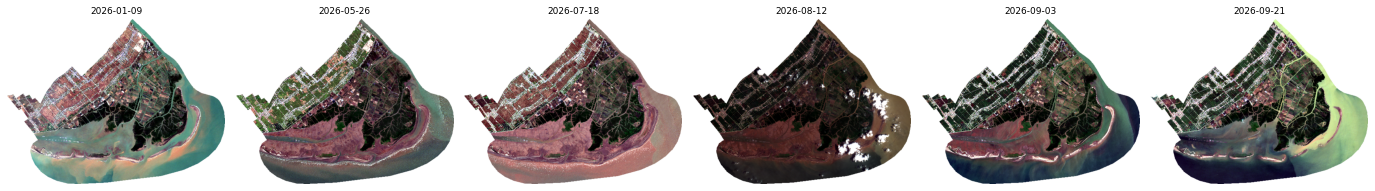

In [9]:
fig, axes = plt.subplots(1, len(TRAIN_IMAGES), figsize=(3.2 * len(TRAIN_IMAGES), 3))
for ax, path in zip(axes, TRAIN_IMAGES):
    show_rgb(path, ax, os.path.basename(path)[10:20], max_size=600)
plt.tight_layout()

Labels and the spatial split: the blue strip is scored during training, the grey guards are never used, and training
windows never overlap the strip. The three rare classes (DK, trống, Gt) each get 416 of the 4,992 training windows.

labelled pixels inside the validation band: 294642


,Anm,Bgt,Dc,Dnn,DK,trống,Gt,Rnm,Stx,Vbn,Vcs
labelled pixels,225470,206045,98169,187393,7435,2865,5633,186812,93650,407939,53507


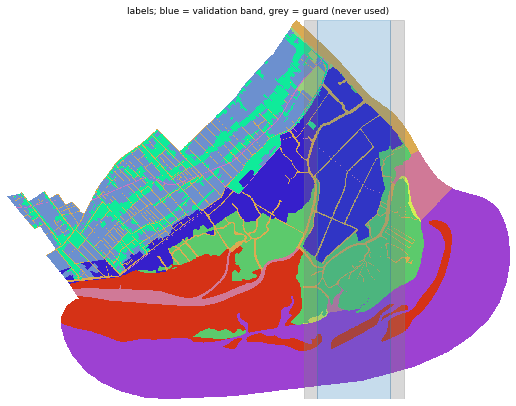

In [10]:
p3 = load_config(P3_CONFIG)
show_split(p3, DATA_ROOT)
label = rasterio.open(os.path.join(DATA_ROOT, p3["label"]["path"])).read(1)
counts = pd.Series({name: int((label == int(code)).sum()) for code, name in p3["class_map"].items()}, name="labelled pixels")
counts.to_frame().T

Radiometry. Values are L2A digital numbers with the +1000 offset of processing baseline 04.00. The reader subtracts it
once, divides by 10,000 and standardises with Prithvi's pretraining mean and std. Check: dark water sits near
reflectance 0 in SWIR, so the 1st percentile (`p1`) of B11 and B12 after the offset is a few tens.

In [11]:
!python scripts/band_statistics.py {q(TRAIN_IMAGES)} --offset -1000 2>/dev/null | tail -8


band      p1  median    p99 rho_mean  z_mean  z_std  (reflectance x 10000)
B02      -30     474   1907   0.0514   -0.25   0.21
B03      300     774   2113   0.0817   -0.24   0.20
B04       62     709   2317   0.0769   -0.30   0.24
B8A      -74    1149   4694   0.1529   -0.65   0.78
B11       15     687   3154   0.0899   -0.85   0.70
B12       20     361   2760   0.0609   -0.72   0.63


## 4. Training

### 4.1 Data audit of the P3 run

Written by the trainer before the first step (`prepared/DATA_AUDIT.json`). The same split, windows and batches are
used by every Xuan Thuy run, also by the U-Net baseline, so validation scores are comparable.

In [12]:
audit = json.load(open(os.path.join(NEW_P3_RUN, "prepared", "DATA_AUDIT.json")))
print({k: audit[k] for k in ["train_pixels", "validation_pixels", "n_patches", "n_batches", "n_validation_windows"]})
pd.DataFrame({"train pixels": audit["train_class_counts"], "loss weight": np.round(audit["class_weights"], 3)},
             index=list(CLASS_MAP.values())).T

{'train_pixels': 1071386, 'validation_pixels': 294156, 'n_patches': 4992, 'n_batches': 312, 'n_validation_windows': 36}


,Anm,Bgt,Dc,Dnn,DK,trống,Gt,Rnm,Stx,Vbn,Vcs
train pixels,87083.000,190976.000,94719.000,183098.000,1015.000,1495.000,4666.000,84044.000,48474.000,326520.000,49296.000
loss weight,0.499,0.337,0.479,0.344,2.542,2.542,2.157,0.508,0.669,0.258,0.664


### 4.2 A 20-step run

Starts from the pretrained Prithvi weights, as a full run does, and stops after 20 optimiser steps (batch of 16
windows each). Shows the loss falling from about ln(11) = 2.4, the time per step and the GPU memory.

In [13]:
SMOKE = os.path.join(RUNS, "_example_smoke")
shutil.rmtree(SMOKE, ignore_errors=True)
mem_log = "/tmp/example_mem.csv"
monitor = subprocess.Popen(["nvidia-smi", "--query-gpu=memory.used,memory.total", "--format=csv,noheader,nounits",
                            "-lms", "500", "-f", mem_log])
!python scripts/train.py --config {P3_CONFIG} --data-root "{DATA_ROOT}" --run-dir "{SMOKE}" --prithvi-weights "{WEIGHTS}" --steps 20 2>&1 | grep -v Warning | tail -12
monitor.terminate(); monitor.wait()
history = pd.read_csv(os.path.join(SMOKE, "training_history.csv"))
sec = history["seconds"].iloc[5:].median()
mem = pd.read_csv(mem_log, header=None, skipinitialspace=True)
RESULTS["seconds per step (P3)"] = round(float(sec), 2)
RESULTS["peak GPU memory MiB (P3)"] = int(mem[0].max())
print(history[["step", "train_WCE", "grad_norm", "seconds"]].iloc[[0, 4, 9, 14, 19]].to_string(index=False))
print(f"\n{sec:.2f} s per step, peak GPU memory {mem[0].max():,} / {mem[1].max():,} MiB")
shutil.rmtree(SMOKE, ignore_errors=True)

  self.scene = TrainingScene(self.config, data_root, verify_checksums)
Optimizer steps: 100%|██████████| 20/20 [01:59<00:00,  5.99s/it]
{
  "step": 20,
  "completed": false,
  "early_stopped": false,
  "best_F1": -1.0,
  "best_accepted_F1": -1.0,
  "method_hash": "154d202a1db75e9b9177e94002c03ce398a98c49625a322ec28adb35d5acd688"
}
 step  train_WCE  grad_norm  seconds
    1   2.569511   2.347629 5.590199
    5   2.215161   1.519334 2.237083
   10   2.012047   1.586258 2.237019
   15   1.854588   1.484845 2.279017
   20   1.656938   1.585877 2.215560

2.22 s per step, peak GPU memory 6,519 / 15,360 MiB


### 4.3 The two completed P3 runs

Same config, data, split and seed number; different code versions and GPUs, so different weight initialisation and
non-deterministic GPU arithmetic. Validation every 156 steps; the checkpoint with the highest macro-F1 is kept;
training stops after 6 validations without a gain of 0.001. The old run kept improving late and reached its best at
step 2,496; the new run plateaued and stopped at step 2,028. Both curves stay within 0.42-0.45 after about step 900.

Text(0.5, 1.0, 'P3 validation macro-F1')

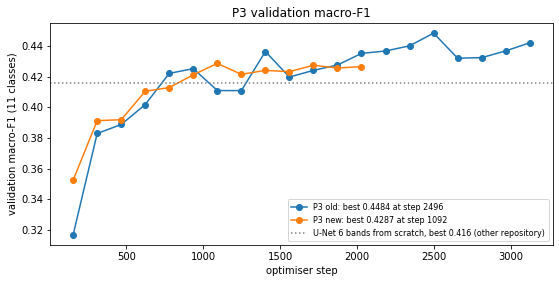

In [14]:
runs = {"P3 old": OLD_P3_RUN, "P3 new": NEW_P3_RUN}
fig, ax = plt.subplots(figsize=(9, 4))
for name, run in runs.items():
    path = os.path.join(run, "validation_history.csv")
    if not os.path.exists(path):
        print(f"{name}: no validation_history.csv in {run}")
        continue
    v = pd.read_csv(path)
    best = v.loc[v["macro_F1_11"].idxmax()]
    RESULTS[f"best val macro-F1 ({name})"] = round(float(best["macro_F1_11"]), 4)
    RESULTS[f"best step ({name})"] = int(best["step"])
    ax.plot(v["step"], v["macro_F1_11"], marker="o", label=f"{name}: best {best['macro_F1_11']:.4f} at step {int(best['step'])}")
ax.axhline(0.4162, ls=":", c="grey", label="U-Net 6 bands from scratch, best 0.416 (other repository)")
ax.set_xlabel("optimiser step"); ax.set_ylabel("validation macro-F1 (11 classes)"); ax.legend(fontsize=8)
ax.set_title("P3 validation macro-F1")

## 5. Xuan Thuy, 1 October 2026: a new date for the same area

Inference with frozen checkpoints, no labels. The scene is covered by 224 x 224 windows every 112 pixels; the
probabilities of overlapping windows are averaged. P2 receives six dates ending on 1 Oct
(30 Mar, 24 May, 18 Jul, 3 Sep, 23 Sep, 1 Oct); some of them are close to the training dates.

In [15]:
XT_1001 = glob.glob(os.path.join(XT_IMAGES, "Sentinel2_2026-10-01_*.tif"))[0]
XT_P2_DATES = ["2026-03-30", "2026-05-24", "2026-07-18", "2026-09-03", "2026-09-23", "2026-10-01"]
XT_P2 = [glob.glob(os.path.join(XT_IMAGES, f"Sentinel2_{d}_*.tif"))[0] for d in XT_P2_DATES]
jobs = {"xt_p3_new": (P3_CONFIG, CKPT["P3 new"], [XT_1001]),
        "xt_p3_old": (P3_CONFIG, CKPT["P3 old"], [XT_1001]),
        "xt_p2_old": (P2_CONFIG, CKPT["P2 old"], XT_P2)}
for out, (config, checkpoint, images) in jobs.items():
    out_dir, images_arg = os.path.join(MAPS, out), q(images)
    !python scripts/predict.py --config {config} --checkpoint "{checkpoint}" --images {images_arg} --out "{out_dir}" > /dev/null 2>&1
    print(out, "->", sorted(os.listdir(out_dir)))
XT = {name: os.path.join(MAPS, out, "2026-10-01_classes.tif")
      for name, out in [("P3 new", "xt_p3_new"), ("P3 old", "xt_p3_old"), ("P2 old", "xt_p2_old")]}

xt_p3_new -> ['2026-10-01_classes.tif', '2026-10-01_entropy.tif', '2026-10-01_max_softmax.tif', '2026-10-01_validity.tif']
xt_p3_old -> ['2026-10-01_classes.tif', '2026-10-01_entropy.tif', '2026-10-01_max_softmax.tif', '2026-10-01_validity.tif']
xt_p2_old -> ['2026-10-01_classes.tif', '2026-10-01_entropy.tif', '2026-10-01_max_softmax.tif', '2026-10-01_validity.tif']


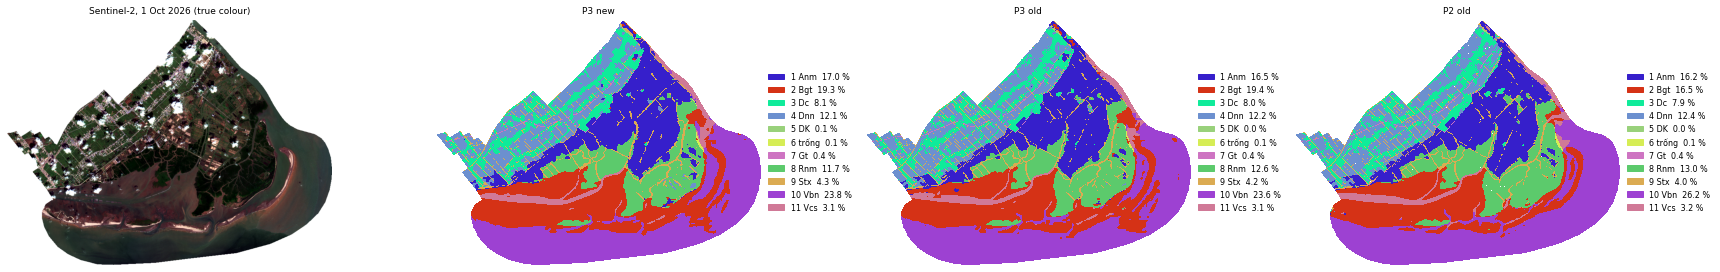

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
show_rgb(XT_1001, axes[0], "Sentinel-2, 1 Oct 2026 (true colour)", max_size=900)
for ax, (name, path) in zip(axes[1:], XT.items()):
    show_map(path, CLASS_MAP, ax, name)
plt.tight_layout()

Where the new P3 model hesitates: normalised entropy of the class probabilities (0 = certain, 1 = uniform).
High values follow class boundaries, narrow channels and the clouds in the north (no cloud mask).

Text(0.5, 1.0, 'P3 new, 1 Oct 2026: normalised entropy')

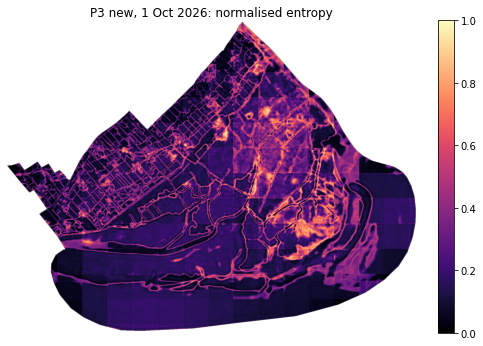

In [17]:
entropy = rasterio.open(XT["P3 new"].replace("_classes", "_entropy")).read(1)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(entropy, cmap="magma", vmin=0, vmax=1); ax.axis("off"); plt.colorbar(im, fraction=0.035)
ax.set_title("P3 new, 1 Oct 2026: normalised entropy")

### 5.2 Checks between maps

1. **Old checkpoints, new code vs old code.** The same weights and images through this package must reproduce the
   maps made by the previous repository (differences only from GPU float16 arithmetic).
2. **New P3 run vs old P3 run.** Two independent trainings: differences in both directions between similar classes,
   at pixels where the model is unsure, are run-to-run noise.
3. **P3 vs P2.** One date vs six dates.

In [18]:
RESULTS["XT 1 Oct: P3 old ckpt, new vs old code (%)"] = round(100 * map_agreement(XT["P3 old"], OLD_MAPS["P3 old 2026-10-01"], CLASS_MAP), 3)
print("\n" + "-" * 60)
RESULTS["XT 1 Oct: P2 old ckpt, new vs old code (%)"] = round(100 * map_agreement(XT["P2 old"], OLD_MAPS["P2 old 2026-10-01"], CLASS_MAP), 3)

no data new / old: 1,030,660 / 1,030,660
agreement: 99.99 % of 1,471,394 pixels

       new %  old %
Anm     16.5   16.5
Bgt     19.4   19.4
Dc       8.0    8.0
Dnn     12.2   12.2
DK       0.0    0.0
trống    0.1    0.1
Gt       0.4    0.4
Rnm     12.6   12.6
Stx      4.2    4.2
Vbn     23.6   23.6
Vcs      3.1    3.1

most frequent changes (old -> new, % of area):
  Vbn      -> Bgt      0.00
  Dc       -> Dnn      0.00
  Bgt      -> Vbn      0.00
  Dnn      -> Stx      0.00
  Bgt      -> Vcs      0.00

------------------------------------------------------------
no data new / old: 1,030,989 / 1,030,989
agreement: 99.99 % of 1,471,065 pixels

       new %  old %
Anm     16.2   16.2
Bgt     16.5   16.5
Dc       7.9    7.9
Dnn     12.4   12.4
DK       0.0    0.0
trống    0.1    0.1
Gt       0.4    0.4
Rnm     13.0   13.0
Stx      4.0    4.0
Vbn     26.2   26.2
Vcs      3.2    3.2

most frequent changes (old -> new, % of area):
  Anm      -> Stx      0.00
  Dnn      -> Dc       0.00
  Vb

In [19]:
RESULTS["XT 1 Oct: P3 new run vs P3 old run (%)"] = round(100 * map_agreement(
    XT["P3 new"], XT["P3 old"], CLASS_MAP, XT["P3 new"].replace("_classes", "_max_softmax")), 1)

no data new / old: 1,030,660 / 1,030,660
agreement: 93.36 % of 1,471,394 pixels

       new %  old %
Anm     17.0   16.5
Bgt     19.3   19.4
Dc       8.1    8.0
Dnn     12.1   12.2
DK       0.1    0.0
trống    0.1    0.1
Gt       0.4    0.4
Rnm     11.7   12.6
Stx      4.3    4.2
Vbn     23.8   23.6
Vcs      3.1    3.1

most frequent changes (old -> new, % of area):
  Bgt      -> Vbn      0.85
  Vbn      -> Bgt      0.54
  Dnn      -> Dc       0.50
  Stx      -> Anm      0.41
  Dc       -> Dnn      0.36

median max-softmax of the new map: where equal 0.93, where different 0.54


In [20]:
RESULTS["XT 1 Oct: P3 new vs P2 old (%)"] = round(100 * map_agreement(XT["P3 new"], XT["P2 old"], CLASS_MAP), 1)

no data new / old: 1,030,660 / 1,030,989
agreement: 90.33 % of 1,471,065 pixels

       new %  old %
Anm     17.0   16.2
Bgt     19.3   16.5
Dc       8.1    7.9
Dnn     12.1   12.4
DK       0.1    0.0
trống    0.1    0.1
Gt       0.4    0.4
Rnm     11.7   13.0
Stx      4.3    4.0
Vbn     23.9   26.2
Vcs      3.1    3.2

most frequent changes (old -> new, % of area):
  Vbn      -> Bgt      2.49
  Dnn      -> Dc       0.75
  Vcs      -> Bgt      0.54
  Dc       -> Dnn      0.50
  Bgt      -> Vbn      0.46


## 6. Thai Thuy, 21 September 2026: a new area without fine-tuning

The Xuan Thuy checkpoints applied to the neighbouring coast of Thai Thuy (Thai Binh). Same date as the training
image, so this tests transfer in space only. The location embedding receives Thai Thuy's coordinates. Several Xuan
Thuy classes do not occur here; the maps are not scored.

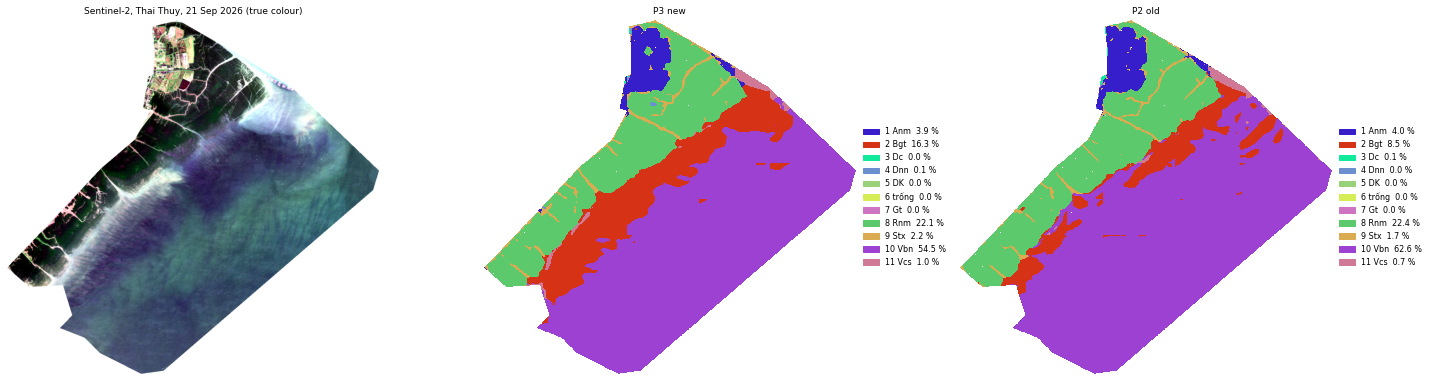

In [21]:
TT_DATES = ["2026-01-09", "2026-05-26", "2026-07-18", "2026-08-12", "2026-09-03", "2026-09-21"]
tt_files = {d: glob.glob(os.path.join(TT_IMAGES, f"Sentinel2_{d}_*.tif")) for d in TT_DATES}
missing = [d for d, f in tt_files.items() if not f]
TT = {}
if missing:
    print("Thai Thuy images missing for", missing, "- section skipped")
else:
    TT_0921 = tt_files["2026-09-21"][0]
    for name, (config, checkpoint, images) in {"P3 new": (P3_CONFIG, CKPT["P3 new"], [TT_0921]),
                                               "P2 old": (P2_CONFIG, CKPT["P2 old"], [tt_files[d][0] for d in TT_DATES])}.items():
        out_dir = os.path.join(MAPS, "tt_" + name.replace(" ", "_").lower())
        images_arg = q(images)
        !python scripts/predict.py --config {config} --checkpoint "{checkpoint}" --images {images_arg} --out "{out_dir}" > /dev/null 2>&1
        TT[name] = os.path.join(out_dir, "2026-09-21_classes.tif")
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    show_rgb(TT_0921, axes[0], "Sentinel-2, Thai Thuy, 21 Sep 2026 (true colour)", max_size=900)
    for ax, (name, path) in zip(axes[1:], TT.items()):
        show_map(path, CLASS_MAP, ax, name)
    plt.tight_layout()

In [23]:
if TT:
    RESULTS["TT 21 Sep: P3 new vs P2 old (%)"] = round(100 * map_agreement(TT["P3 new"], TT["P2 old"], CLASS_MAP), 1)

no data new / old: 646,695 / 646,753
agreement: 87.61 % of 642,959 pixels

       new %  old %
Anm      3.9    4.0
Bgt     16.3    8.5
Dc       0.0    0.1
Dnn      0.1    0.0
DK       0.0    0.0
trống    0.0    0.0
Gt       0.0    0.0
Rnm     22.1   22.4
Stx      2.2    1.7
Vbn     54.5   62.6
Vcs      1.0    0.7

most frequent changes (old -> new, % of area):
  Vbn      -> Bgt      8.95
  Bgt      -> Vbn      0.98
  Rnm      -> Stx      0.60
  Bgt      -> Vcs      0.23
  Bgt      -> Rnm      0.22


## 7. Summary

All numbers below were computed in this run. Reference outside this repository:
U-Net 6 bands trained from scratch on the same split, best validation macro-F1 0.416.

In [25]:
print(json.dumps(CONTEXT, indent=1, ensure_ascii=False))
pd.Series(RESULTS, name="value").to_frame()

{
 "date (UTC)": "2026-10-29 17:08",
 "commit": "f9e227e Rewrite notebook quickstart and cleanup",
 "prithvi_unet": "1.1.1",
 "gpu": "Tesla T4, 15360 MiB",
 "python": "3.13.16",
 "torch": "2.11.0+cu130",
 "terratorch": "1.2.12",
 "timm": "1.0.30",
 "numpy": "2.5.4",
 "rasterio": "1.5.2",
 "pandas": "2.2.3"
}


,value
seconds per step (P3),2.2200
peak GPU memory MiB (P3),6519.0000
best val macro-F1 (P3 old),0.4484
best step (P3 old),2496.0000
best val macro-F1 (P3 new),0.4287
best step (P3 new),1092.0000
"XT 1 Oct: P3 old ckpt, new vs old code (%)",99.9920
"XT 1 Oct: P2 old ckpt, new vs old code (%)",99.9940
XT 1 Oct: P3 new run vs P3 old run (%),93.4000
XT 1 Oct: P3 new vs P2 old (%),90.3000


---
**Saving this example (maintainers).** *File > Download > .ipynb*, put it at
`notebooks/examples/xuanthuy_example.ipynb`, then run `python scripts/clean_notebook.py notebooks/examples/xuanthuy_example.ipynb`
(removes progress-bar noise, checks for tokens and size) before committing.